# Subjective Weights in Multi-Criteria Decision Making (MCDM)

Subjective weights determination represent the importance assigned to criteria based on the preferences, judgments, or knowledge of decision-makers. Unlike objective weighting methods, where the weights are derived from the intrinsic properties of the data (e.g., entropy or correlation), subjective weights rely on human input and are influenced by experience, priorities, or specific decision-making contexts.

Some common techniques for subjective weight determination include:
- **Direct Assignment**: Decision-makers assign weights directly to criteria based on their judgment.
- **Pairwise Comparison (e.g., AHP)**: Decision-makers evaluate the relative importance of criteria in pairs to derive consistent weights.
- **Scoring Methods**: A fixed number of points is distributed among criteria to reflect their importance.
- **Ranking Methods**: Criteria are ranked in order of importance, and weights are assigned based on the ranks.

Subjective weight determination allows for flexibility and customization of the decision-making process, making it highly applicable in scenarios where decision-maker of expert input is vital.

## Pairwise Comparison-Based methods

The `pymcdm` library provides two methods for determining subjective weights based on the complete matrix of pairwise comparisons: AHP (Analytic Hierarchy Process) and RANCOM (RANking COMparison). Methods which need less information from the decision-maker are presented in the section [Other subjective weighting methods](#Other-subjective-weighting-methods). In this example, we will demonstrate how to use the `pymcdm` library to apply both AHP and RANCOM for subjective weight determination, providing practical guidance on their usage.

### AHP

The implementation of AHP (Analytic Hierarchy Process) in the `pymcdm` library is designed with specific assumptions and features. 

1. For now only a 1-layer structure, meaning that all criteria are evaluated at the same hierarchical level without incorporating sub-criteria.
2. Weights are calculated from the AHP pairwise maitrix using the eigenvector method.
3. Pairwise comparison matrix accepts values from a predefined scale of 1 to 9 and their reciprocals (1/9 to 1), where 1 indicates equal importance between two criteria, and values like 9 and 1/9 represent extreme importance of one criterion over another and vice versa. I.e. possible values in the matrix are following: `{1, 2, 3, 4, 5, 6, 7, 8, 9, 1/2, 1/3, 1/4, 1/5, 1/6, 1/7, 1/8, 1/9}`.

For both AHP and RANCOM methods, method's object can be instantiated using:
- Scores - provide scores for each criterion as `np.array()`. Larger values indicates more important criteria.
- Ranking - provide ranking for each criterion as `np.array()`. Smaller values indicates more important criteria.
- Comparison matrix - input complete matrix. Note, that matrix is validated to check if all values are fits in 1-9 Saaty scale.
- Text file with comparison matrix, in `.csv` format. Same validation is applied as in case of comparison matrix.
- Manual comparison via command line interface.

In [1]:
# Essential imports
import numpy as np
from pymcdm.weights.subjective import AHP, RANCOM

In [2]:
# Suppose we have three criteria to evaluate. Define the scoring vector for them:
scores = np.array([10, 3, 5])
# You can use any positive numbers above zero to define scoring vector.

# Create AHP object:
ahp = AHP(scoring=scores)  # Note that only one argument can be provided.
weights = ahp()  # Call the object to get weights.
print(weights)

[0.44342911 0.16919987 0.38737101]


In [3]:
# Suppose we have three criteria to evaluate. Define the ranking vector for them:
ranking = np.array([1, 3, 2])
# You can use any positive numbers above zero to define ranking vector.

ahp = AHP(ranking=ranking)
weights = ahp()  # Call the object to get weights.
print(weights)

[0.54994561 0.20984352 0.24021087]


In [4]:
# Sometimes you can want to use prepared matrix to instantiate AHP object:
a = np.array([
    [  1, 1/2,   7],
    [  2,   1,   3],
    [1/7, 1/3,   1]
])

ahp = AHP(matrix=a)
weights = ahp()
print(weights)

[0.41058565 0.49139587 0.09801848]


The comparison matrix can be presented with `pairwise_matrix`, which writes the reciprocals of the Saaty scale as
fractions and colours the cells by the logarithm of the comparisons, so that a comparison and its reciprocal are
equally far from the diagonal. The consistency ratio is given in the title: it is above 0.1 for this matrix, so by
the usual rule of AHP its comparisons should be revised.

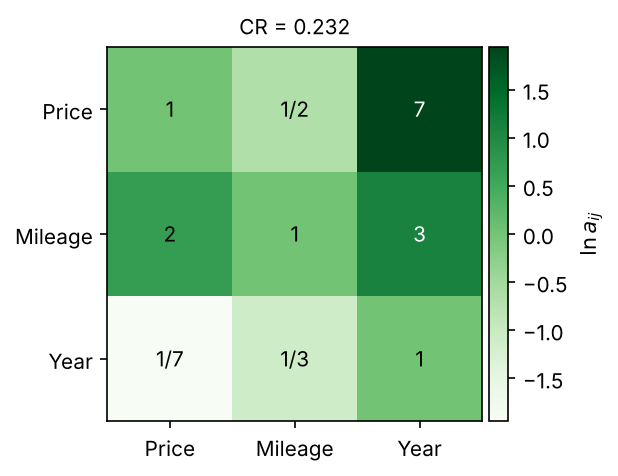

In [5]:
import matplotlib.pyplot as plt
from pymcdm.visuals import pairwise_matrix

fig, ax = plt.subplots(figsize=(4, 3.5), dpi=150)
pairwise_matrix(ahp.matrix, labels=['Price', 'Mileage', 'Year'], colorbar=True, ax=ax)
ax.set_title(f'CR = {ahp.get_cr():.3f}', fontsize=10)
plt.tight_layout()
plt.show()

In [6]:
# And there are also command line interface to fill pairwise matrix step-by-step. See the output below.
criteria_names = ['Price', 'Mileage', 'Year']
ahp = AHP(object_names=criteria_names)
weights = ahp()  # Command line interface for matrix filling starts here.
print(weights)
print(ahp.get_cr())  # To check CR use get_cr() method
ahp.to_csv('ahp_matrix.csv')  # Don't forget to save your matrix for later usage.

Please compare two objects:
Choose values in scale from 1 to 9 where:
  1: if "Price" is equally important to "Mileage";
  3: if "Price" is weakly preferred than to "Mileage";
  5: if "Price" is strongly preferred than to "Mileage";
  7: if "Price" is very strongly preferred than to "Mileage";
  9: if "Price" is extremely more important than "Mileage";
OR value in scale 1 to 1/9 where:
  1: if "Mileage" is equally important to "Price";
1/3: if "Mileage" is weakly preferred than to "Price";
1/5: if "Mileage" is strongly preferred than to "Price";
1/7: if "Mileage" is very strongly preferred than to "Price";
1/9: if "Mileage" is extremely more important than "Price".



Your answer:  5


Please compare two objects:
Choose values in scale from 1 to 9 where:
  1: if "Price" is equally important to "Year";
  3: if "Price" is weakly preferred than to "Year";
  5: if "Price" is strongly preferred than to "Year";
  7: if "Price" is very strongly preferred than to "Year";
  9: if "Price" is extremely more important than "Year";
OR value in scale 1 to 1/9 where:
  1: if "Year" is equally important to "Price";
1/3: if "Year" is weakly preferred than to "Price";
1/5: if "Year" is strongly preferred than to "Price";
1/7: if "Year" is very strongly preferred than to "Price";
1/9: if "Year" is extremely more important than "Price".



Your answer:  1/2


Please compare two objects:
Choose values in scale from 1 to 9 where:
  1: if "Mileage" is equally important to "Year";
  3: if "Mileage" is weakly preferred than to "Year";
  5: if "Mileage" is strongly preferred than to "Year";
  7: if "Mileage" is very strongly preferred than to "Year";
  9: if "Mileage" is extremely more important than "Year";
OR value in scale 1 to 1/9 where:
  1: if "Year" is equally important to "Mileage";
1/3: if "Year" is weakly preferred than to "Mileage";
1/5: if "Year" is strongly preferred than to "Mileage";
1/7: if "Year" is very strongly preferred than to "Mileage";
1/9: if "Year" is extremely more important than "Mileage".



Your answer:  7


[0.43298618 0.35689191 0.21012191]
2.038220426046577


In [7]:
# Now, with previously saved matrix you can skip questions if needed:
ahp = AHP(filename='ahp_matrix.csv')
print(ahp())

[0.43298618 0.35689191 0.21012191]


### RANCOM

The implementation of the RANCOM (RANking COMparison) in the `pymcdm` library is designed with specific features.

For both AHP and RANCOM methods, method's object can be instantiated using:
- Scores - provide scores for each criterion as `np.array()`. Larger values indicates more important criteria.
- Ranking - provide ranking for each criterion as `np.array()`. Smaller values indicates more important criteria.
- Comparison matrix - input complete matrix. Note, that matrix is validated to check if all values are fits in 1-9 Saaty scale.
- Text file with comparison matrix, in `.csv` format. Same validation is applied as in case of comparison matrix.
- Manual comparison via command line interface.

In [8]:
# Suppose we have three criteria to evaluate. Define the scoring vector for them:
scores = np.array([10, 3, 5])
# You can use any positive numbers above zero to define scoring vector.

# Create RANCOM object:
rancom = RANCOM(scoring=scores)  # Note that only one argument can be provided.
weights = rancom()  # Call the object to get weights.
print(weights)

[0.55555556 0.11111111 0.33333333]


In [9]:
# Suppose we have three criteria to evaluate. Define the ranking vector for them:
ranking = np.array([1, 3, 2])
# You can use any positive numbers above zero to define ranking vector.

rancom = RANCOM(ranking=ranking)
weights = rancom()  # Call the object to get weights.
print(weights)

[0.55555556 0.11111111 0.33333333]


In [10]:
# And there are also command line interface  to fill pairwise matrix step-by-step. See the output below.
criteria_names = ['Price', 'Mileage', 'Year']
rancom = RANCOM(object_names=criteria_names)
weights = rancom()  # Command line interface  for matrix filling starts here.
print(weights)
rancom.to_csv('rancom_matrix.csv')  # Don't forget to save your matrix for later usage.

Please compare two objects:
Choose:
  1: if "Price" is more important than "Mileage";
1/2: if "Price" is equally important to "Mileage";
  0: if "Mileage" is more important than "Price".



Your answer:  1


Please compare two objects:
Choose:
  1: if "Price" is more important than "Year";
1/2: if "Price" is equally important to "Year";
  0: if "Year" is more important than "Price".



Your answer:  1/2


Please compare two objects:
Choose:
  1: if "Mileage" is more important than "Year";
1/2: if "Mileage" is equally important to "Year";
  0: if "Year" is more important than "Mileage".



Your answer:  1


[0.44444444 0.33333333 0.22222222]


In [11]:
# Now, with previously saved matrix you can skip questions if needed:
rancom = RANCOM(filename='rancom_matrix.csv')
print(rancom())

[0.44444444 0.33333333 0.22222222]


## Other subjective weighting methods

Besides AHP and RANCOM, `pymcdm.weights.subjective` provides methods which need less information from the
decision-maker than a complete pairwise comparison matrix. They differ mainly in the kind of judgments they ask for:

| Input of the decision-maker | Methods |
|---|---|
| Comparisons with the best (and the worst) criterion | `BWM`, `BCM`, `LBWA` |
| Ranking of criteria and comparisons of consecutive criteria | `SWARA`, `PIPRECIA`, `FUCOM`, `COBRAC` |
| Ranking of criteria only | `ROC`, `RS`, `RR`, `RE` |
| Ranking of criteria with "white cards" between them | `SIMOS`, `SRF` |
| Comparisons with the vital and the immaterial criterion | `VIMM` |
| Decision matrix with thresholds or opinions | `ITARA`, `OWCM` |

All of them are used in the same way: the judgments are passed to the constructor and the object is called to
obtain the weights, which sum to 1. Criteria are always given by their indices, starting from 0.

Unless stated otherwise, the examples below are the numerical examples of the papers which introduced the methods,
so the weights can be compared with the publications (the same examples are used in the tests of the library).

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymcdm.weights.subjective import (BWM, BCM, LBWA, SWARA, PIPRECIA, FUCOM, COBRAC,
                                       ROC, RS, RR, RE, SIMOS, SRF, VIMM, ITARA, OWCM)
from pymcdm.visuals import weights_intervals, simos_cards

### Comparisons with the best criterion: BWM, BCM and LBWA

In **BWM** (Best-Worst Method) the decision-maker selects the best and the worst criterion and compares the best
criterion with all the others (`a_b`) and all the others with the worst one (`a_w`), using numbers from 1 to 9.
Weights are obtained by minimizing the largest deviation of the weight ratios from these comparisons; the
optimal deviation $\xi$ (`get_xi()`) measures the inconsistency of the comparisons.

The example below is Example 1 of Rezaei (2015): three criteria, $C_3$ is the best and $C_1$ the worst criterion.

In [13]:
bwm = BWM(a_b=[8, 2, 1], a_w=[1, 5, 8])
print('Weights:', np.round(bwm(), 4))
print('xi:', round(bwm.get_xi(), 4))

Weights: [0.0714 0.3387 0.5899]
xi: 0.2583


The original (nonlinear) model of BWM can have several optimal solutions if the comparisons are not fully
consistent and there are more than three criteria. The ranges of the optimal weights are given by
`get_weight_intervals()`. The linear model of BWM (`model='linear'`) always has a unique solution. The example is
Example 2 of Rezaei (2016) with five criteria.

In [14]:
bwm = BWM(a_b=[2, 1, 4, 3, 8], a_w=[4, 8, 2, 3, 1])
lower, upper = bwm.get_weight_intervals()
print('Lower bounds:', np.round(lower, 4))
print('Upper bounds:', np.round(upper, 4))

bwm.model = 'linear'
print('Linear BWM:  ', np.round(bwm(), 4), ' xi =', round(bwm.get_xi(), 4))

Lower bounds: [0.2145 0.4461 0.1085 0.1563 0.0548]
Upper bounds: [0.2289 0.4571 0.1176 0.1602 0.0561]
Linear BWM:   [0.2295 0.4481 0.1148 0.153  0.0546]  xi = 0.0109


The intervals of the optimal weights can be presented with `weights_intervals`. Example 3 of Rezaei (2016) has
less consistent comparisons, so its intervals are wider and some of them overlap; the markers show the weights
returned by the nonlinear model.

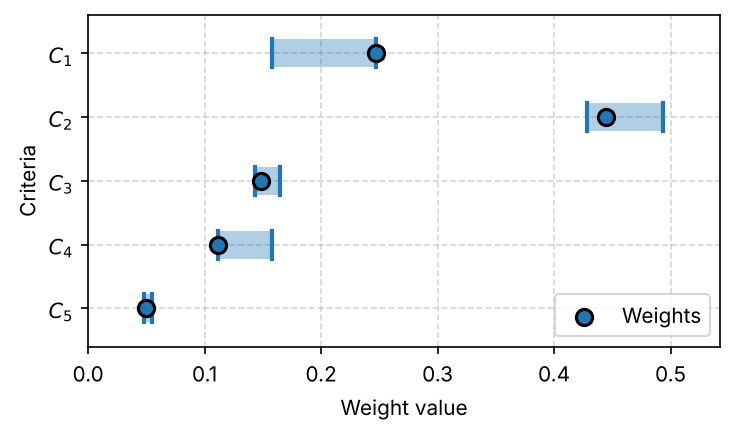

In [15]:
bwm = BWM(a_b=[2, 1, 4, 3, 8], a_w=[4, 8, 4, 2, 1])
lower, upper = bwm.get_weight_intervals()

fig, ax = plt.subplots(figsize=(5, 3), dpi=150)
weights_intervals(lower, upper, bwm(), ax=ax)
plt.tight_layout()
plt.show()

**BCM** (Base-Criterion Method) needs only one vector: the comparisons of a chosen base-criterion with all the
others. It is fully consistent by construction ($\xi = 0$). Example 1 of Haseli et al. (2020) uses the same
problem as the BWM example above, with $C_3$ as the base-criterion.

In [16]:
bcm = BCM(a_b=[8, 2, 1])
print('Weights:', np.round(bcm(), 4))
print('xi:', round(bcm.get_xi(), 4))

Weights: [0.0769 0.3077 0.6154]
xi: 0.0


In **LBWA** (Level Based Weight Assessment) criteria are first grouped into levels of significance (`i`, the
first level contains the most important criterion) and then compared with the most important criterion with
integer values (`l`, given in the same order as the criteria in `i`). The elasticity coefficient `r0` allows
to fine-tune the weights. Example 1 of Žižović & Pamučar (2019) has eight criteria in two levels:

In [17]:
lbwa = LBWA(i=[[1, 4, 6, 5, 0, 2], [7, 3]], l=[0, 2, 3, 4, 4, 5, 1, 2], r0=7)
print('Weights:', np.round(lbwa(), 3))

Weights: [0.121 0.191 0.111 0.084 0.148 0.121 0.134 0.089]


### Ranking and comparisons of consecutive criteria: SWARA, PIPRECIA, FUCOM and COBRAC

These methods start from the ranking of criteria (indices in decreasing order of importance) and ask for one
judgment for each pair of consecutive criteria:

- **SWARA**: how much more important is the criterion than the next one (`s_v`, 0 means equally important).
- **PIPRECIA**: relative importance of the next criterion compared to the previous one (`s_v` in (0, 2), 1 means
  equally important). Unlike SWARA, the next criterion can also be more important. With `comparison='first'`
  every criterion is compared with the first one (PIPRECIA-S).
- **FUCOM**: comparative priorities $\varphi_{k/(k+1)} \geq 1$ (`i`), or significance scores of the criteria (`v`).
  The deviation from full consistency is available as `dfc`.
- **COBRAC**: share `xi` of the importance of the more important criterion in each pair, i.e.
  $w_i : w_j = \xi : (1 - \xi)$. Pairs do not have to be consecutive and can be inconsistent; the largest deviation
  is given by `get_delta()`.

In [18]:
# Keršulienė et al. (2010), Table 1: six attributes of dispute resolution methods
swara = SWARA(s=[0, 1, 2, 3, 4, 5], s_v=[0.15, 0.04, 0.29, 0.02, 0.04])
print('SWARA:     ', np.round(swara(), 2))

# Stanujkić et al. (2021), Table 2: PIPRECIA
piprecia = PIPRECIA(s=[0, 1, 2, 3], s_v=[1.0, 0.5, 0.5])
print('PIPRECIA:  ', np.round(piprecia(), 2))

# Pamučar et al. (2018), Example 1: comparative priorities given directly
fucom = FUCOM(o=[0, 1, 2, 3], i=[1.08, 1.25, 1.45])
print('FUCOM:     ', np.round(fucom(), 3), ' DFC =', round(fucom.dfc, 4))

# Illustrative consistent comparisons C1 > C2 > C3 with shares 0.7 and 0.6
# (the example of Pamucar et al. (2024) has 30 sub-criteria)
cobrac = COBRAC(n_criteria=3, pairs=[(0, 1), (1, 2)], xis=[0.7, 0.6])
print('COBRAC:    ', np.round(cobrac(), 4))

SWARA:      [0.22 0.19 0.18 0.14 0.14 0.13]
PIPRECIA:   [0.32 0.32 0.21 0.14]
FUCOM:      [0.315 0.291 0.233 0.161]  DFC = 0.0
COBRAC:     [0.5833 0.25   0.1667]


If an additional, inconsistent comparison is given to COBRAC, the weights are a compromise and `get_delta()`
returns the largest deviation of the weight ratios from the comparisons:

In [19]:
cobrac = COBRAC(n_criteria=3, pairs=[(0, 1), (1, 2), (0, 2)], xis=[0.7, 0.6, 0.6])
print('Weights:', np.round(cobrac(), 4))
print('delta:', round(cobrac.get_delta(), 3))

Weights: [0.4893 0.2607 0.25  ]
delta: 0.457


### Ranking of criteria only: ROC, RS, RR and RE

When the decision-maker can only rank the criteria, weights can be approximated from the ranks: rank order
centroid (`ROC`), rank sum (`RS`), rank reciprocal (`RR`) and rank exponent (`RE`, with exponent `z` given
directly or found from the weight of the most important criterion, `w_top`). The example uses the ranking of
seven criteria of Stillwell et al. (1981), Table 6.

In [20]:
order = [3, 0, 5, 4, 2, 1, 6]  # criteria indices from the most to the least important

rank_weights = pd.DataFrame({
    'ROC': ROC(order)(),
    'RS': RS(order)(),
    'RR': RR(order)(),
    'RE (z=1.16)': RE(order, z=1.16)(),
}, index=[f'C{i + 1}' for i in range(7)])
rank_weights.round(3)

,ROC,RS,RR,RE (z=1.16)
C1,0.228,0.214,0.193,0.223
C2,0.044,0.071,0.064,0.062
C3,0.073,0.107,0.077,0.100
C4,0.370,0.250,0.386,0.267
C5,0.109,0.143,0.096,0.139
C6,0.156,0.179,0.129,0.181
C7,0.020,0.036,0.055,0.028


### Cards: SIMOS and SRF

In the Simos procedure the decision-maker places cards with the criteria from the least to the most important
one (`r`, tied criteria in one inner list) and inserts white cards between the positions (`w_c`) to show bigger
differences of importance. `SRF` is the revised procedure of Figueira & Roy (2002), which additionally asks for
the ratio `z` between the weights of the most and the least important criterion and rounds the weights (in
percent) to `w` decimal places, so that they sum to exactly 100. Both examples use the twelve criteria
$a, \ldots, l$ of Figueira & Roy (2002).

In [21]:
r = [[2, 6, 11], [3], [1, 5, 8, 9], [4], [0, 7], [10]]  # from the least to the most important
w_c = [0, 1, 0, 0, 0]                                     # one white card between the 2nd and 3rd position

cards = pd.DataFrame({
    'SIMOS': 100 * SIMOS(r=r, w_c=w_c)(),
    'SRF (z=6.5)': 100 * SRF(r=r, w_c=w_c, z=6.5, w=1)(),
}, index=list('abcdefghijkl'))
cards.round(3).T

,a,b,c,d,e,f,g,h,i,j,k,l
SIMOS,13.372,8.721,2.326,4.651,11.628,8.721,2.326,13.372,8.721,8.721,15.116,2.326
SRF (z=6.5),13.200,8.900,2.400,4.500,11.000,8.900,2.400,13.200,8.900,8.900,15.300,2.400


`simos_cards` shows the cards as the decision-maker placed them: criteria of the same importance are stacked, the
white card is drawn with a dashed line, the colour of a card grows with its importance, and the weights (here of
SRF) are written under the positions.

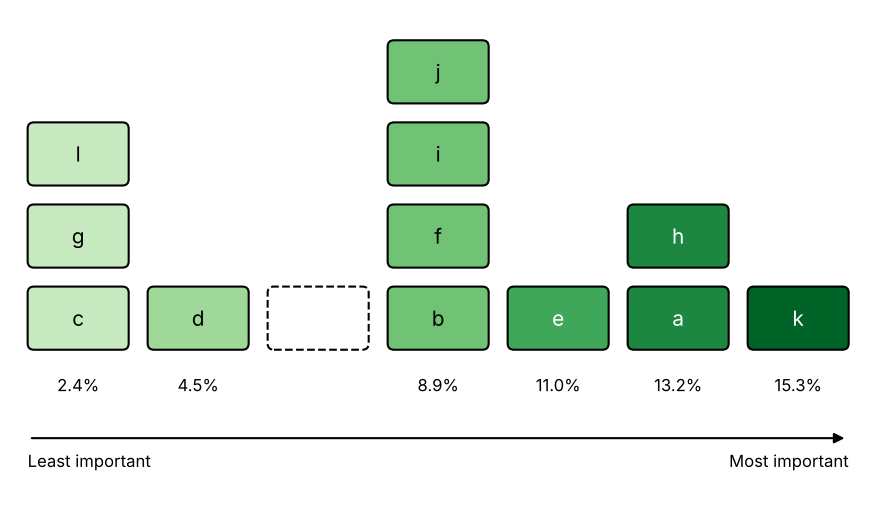

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=150)
simos_cards(r, w_c, weights=SRF(r=r, w_c=w_c, z=6.5, w=1)(), labels=list('abcdefghijkl'), ax=ax)
plt.tight_layout()
plt.show()

### Vital and immaterial criteria: VIMM

In VIMM the decision-maker selects the most impactful (vital) and the least impactful (immaterial) criterion and
compares them with the remaining criteria on a scale from 2 to 9. The procedure is repeated in rounds for the
criteria which remain. Example 1 of Zakeri et al. (2023): seven criteria of supplier selection (cost, quality,
delivery, service, social responsibility, risk, agility), cost is vital and social responsibility immaterial.

In [23]:
vimm = VIMM(n_criteria=7, vital_index=0, immaterial_index=4,
            c_vital=[[9, 7.5, 8, 6.5, 7], [8, 8.5, 7]],
            c_immaterial=[[9, 8, 8.5, 6, 7.5], [8.5, 9, 8]])
print('Weights:', np.round(vimm(), 3))

Weights: [0.286 0.243 0.186 0.192 0.014 0.027 0.05 ]


### Judgments about the decision matrix: ITARA and OWCM

**ITARA** uses the decision matrix and an indifference threshold for each criterion: criteria whose values
differ less than the threshold obtain small (or zero) weights. The example is the location selection in banking
of Hatefi (2019), Table 1.

**OWCM** uses an opinion matrix, in which each alternative is compared with the ideal solution on every
criterion on a five-point scale (1 - no difference, 5 - huge difference). The example is the comparison of
machine learning methods of Ahmed Mandil et al. (2024), Table 6.

In [24]:
matrix = np.array([
    [7400000, 98.4, 73.1, 50800, 4.1, 90.1, 2.4, 20.4, 393, 10.6, 3.5],
    [33500000, 78.2, 66.5, 144600, 4.1, 84, 6.4, 10.1, 347, 8, 1.83],
    [10850000, 96, 61.4, 255000, 4, 75.6, 1.1, 10.4, 275, 6.3, 7.52],
    [29200, 86.6, 82.3, 657000, 5.6, 89.3, 4.6, 21.4, 150, 12.9, 3.99],
])
itara = ITARA(t=[1000000, 10, 10, 50000, 0, 0, 2, 7, 50, 2, 3], p=1)
print('ITARA:', np.round(itara(matrix), 3))

opinions = np.array([
    [5, 4, 1, 1, 1, 1, 1, 2, 1],
    [4, 5, 1, 2, 2, 2, 2, 1, 2],
    [2, 4, 2, 2, 3, 2, 3, 2, 3],
    [1, 5, 2, 3, 4, 3, 4, 3, 3],
    [3, 4, 2, 3, 4, 3, 4, 2, 3],
    [2, 4, 3, 4, 5, 4, 5, 5, 4],
    [3, 1, 5, 4, 5, 4, 5, 4, 4],
    [3, 3, 5, 5, 5, 5, 5, 5, 5],
])
print('OWCM: ', np.round(OWCM(M=opinions)(), 4))

ITARA: [0.441 0.    0.    0.309 0.067 0.032 0.01  0.036 0.062 0.018 0.024]
OWCM:  [0.1383 0.1322 0.0698 0.1273 0.0894 0.1273 0.0894 0.0881 0.1383]


### Comparison of the methods

Methods which take the same kind of input can be compared directly. Below, four criteria are ranked
$C_1 \succ C_2 \succ C_3 \succ C_4$ and each method gets the judgments it needs. The rank-based methods use only
the ranking, while the other methods also use the intensity of preferences: each criterion is twice as important
as the next one.

In [25]:
order = [0, 1, 2, 3]

methods = {
    'ROC': ROC(order),
    'RS': RS(order),
    'RR': RR(order),
    'SWARA': SWARA(s=order, s_v=[1, 1, 1]),
    'PIPRECIA': PIPRECIA(s=order, s_v=[0.5, 0.5, 0.5]),
    'FUCOM': FUCOM(o=order, i=[2, 2, 2]),
    'BWM': BWM(a_b=[1, 2, 4, 8], a_w=[8, 4, 2, 1]),
    'BCM': BCM(a_b=[1, 2, 4, 8]),
    'COBRAC': COBRAC(n_criteria=4, pairs=[(0, 1), (1, 2), (2, 3)], xis=[2 / 3, 2 / 3, 2 / 3]),
}
comparison = pd.DataFrame({name: method() for name, method in methods.items()},
                          index=['C1', 'C2', 'C3', 'C4'])
comparison.round(4)

,ROC,RS,RR,SWARA,PIPRECIA,FUCOM,BWM,BCM,COBRAC
C1,0.5208,0.4,0.48,0.5333,0.4154,0.5333,0.5333,0.5333,0.5333
C2,0.2708,0.3,0.24,0.2667,0.2769,0.2667,0.2667,0.2667,0.2667
C3,0.1458,0.2,0.16,0.1333,0.1846,0.1333,0.1333,0.1333,0.1333
C4,0.0625,0.1,0.12,0.0667,0.1231,0.0667,0.0667,0.0667,0.0667


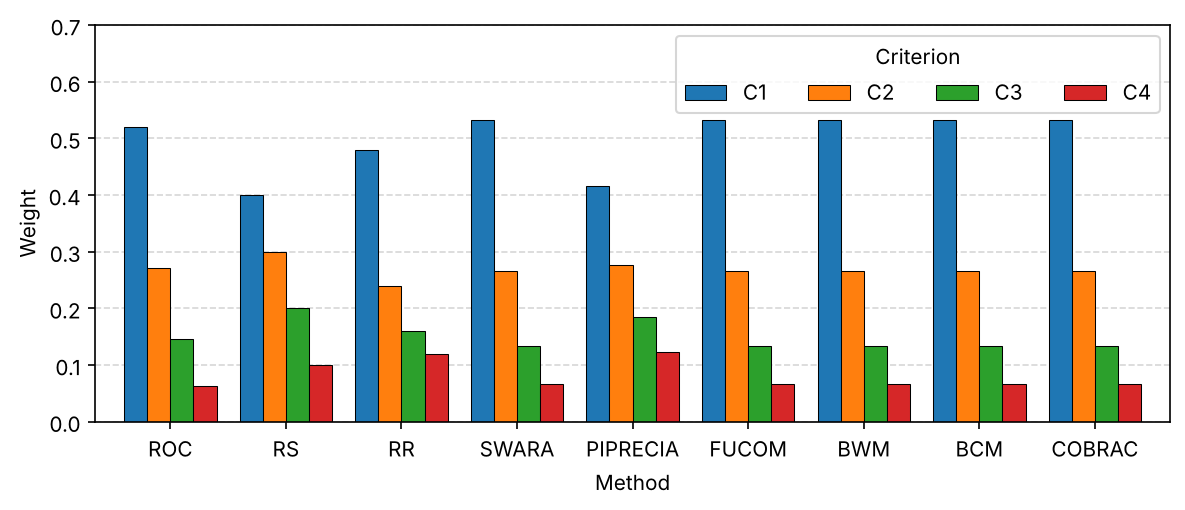

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.5), dpi=150)
comparison.T.plot.bar(ax=ax, width=0.8, edgecolor='k', linewidth=0.5)
ax.set_ylabel('Weight')
ax.set_xlabel('Method')
ax.tick_params(axis='x', rotation=0)
ax.grid(alpha=0.5, linestyle='--', axis='y')
ax.set_axisbelow(True)
ax.set_ylim(0, 0.7)
ax.legend(title='Criterion', ncol=4, loc='upper right')
plt.tight_layout()
plt.show()

With consistent judgments that the next criterion is two times less important, SWARA, FUCOM, BWM, BCM and COBRAC
give the same weights $w_j \propto 2^{-j}$, as they should. PIPRECIA gives flatter weights: its value
$s_j = 0.5$ ("half as important") is turned into the coefficient $k_j = 2 - s_j = 1.5$, so consecutive weights
differ 1.5 times, and no value of $s_j \in (0, 2)$ gives the ratio 2. The same words of the decision-maker can
therefore lead to different weights in different methods. The rank-based methods do not know the
intensity of preferences, so their weights are flatter (RS, RR) or steeper (ROC) depending on the assumed
distribution of the weights.